# Fitting TCM-SR on real replay: Pfeiffer & Foster Rat1 / Linear1

This is an example of fitting the hierarchical HMM to replay data from a linear track. We analyze hippocampal population bursts (PBEs) from Rat1 / Linear1 of the Pfeiffer & Foster (2015) dataset. The rat runs back and forth on a linear track and is rewarded at both ends.

The steps are:

1. Unfold the track into one directed coordinate $u$, the directed loop of the simulation notebooks: outbound runs on $[0, L]$ and inbound runs on $[L, 2L]$. This makes the animal's movement matrix $P$ directional.
2. Fit place fields on running, and fit $P$ on all behavior, including the stops at the track ends.
3. Check that the place fields decode the animal's position on held-out laps.
4. Fit `gamma` and `asymmetry` by EM on half of the replay events (here, population bursts or PBEs), and check the EM estimate against a direct maximization of the marginal likelihood.
5. Compare the held-out event likelihood of the EM-fitted `TCM_SR` with the starting `TCM_SR` and with a `RandomWalk` continuous dynamic.

The model has three dynamics: stationary (`Identity`), TCM-SR (`TCM_SR`) and fragmented (`Uniform`). The discrete transition between them is held fixed at `DiagonalDiscrete(0.98)`.

**Using your own data.** Only the cell under *Load the data* knows about this dataset. It defines a few plain arrays: tracking, spike times per unit, and the start and end of each replay event. Replace that cell with one that defines the same variables for your recording, and the rest of the notebook runs unchanged. The notebook assumes a linear track, with position measured from one end.

In [1]:
%load_ext autoreload
%autoreload 2

import contextlib
import io
import logging
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set(style='white', context='paper', font_scale=1.0)
logging.basicConfig(level=logging.WARNING)
np.random.seed(0)

## Settings

These settings apply to any dataset.

* `DECODE_BIN_S` is both the encoding bin and the decoding bin.
* `PLACE_BIN_SIZE_CM` is the spatial bin of the decoder, and `POSITION_STD_CM` is the KDE bandwidth of the place fields.
* `END_ZONE_CM` marks the two track ends, which are used to find where the animal turns around.
* `RUN_SPEED_CM_S` is the running threshold for the place fields. Speed is the derivative of position after smoothing it over `POSITION_SMOOTH_SAMPLES` tracking samples.
* `MOVEMENT_TIME_STEP_S` is the time step of $P$. The horizon is $\text{step} / (1 - \gamma)$.
* EM starts from `INITIAL_GAMMA` and `INITIAL_ASYMMETRY`, and runs for at most `EM_MAX_ITER` iterations. It stops earlier once the data log likelihood changes by less than `EM_TOLERANCE` (relative).
* `DISCRETE_DIAGONAL` is the probability of staying in the same dynamic from one bin to the next. It is held fixed.

In [2]:
DECODE_BIN_S = 0.003          # encoding and decoding time bin (s)
PLACE_BIN_SIZE_CM = 4.0       # spatial bin of the decoder
POSITION_STD_CM = 3.0         # KDE bandwidth of the place fields
END_ZONE_CM = 20.0            # extent of each track end
RUN_SPEED_CM_S = 5.0          # running threshold for the place fields
POSITION_SMOOTH_SAMPLES = 3   # Gaussian smoothing of position before taking speed, in samples
MOVEMENT_TIME_STEP_S = 0.1    # time step of the movement matrix P
INITIAL_GAMMA, INITIAL_ASYMMETRY = 0.7, 0.5
DISCRETE_DIAGONAL = 0.98
EM_MAX_ITER = 30
EM_TOLERANCE = 1e-6           # relative change in data log likelihood
STATE_NAMES = ['stationary', 'tcm_sr', 'fragmented']

SAMPLING_FREQUENCY = 1.0 / DECODE_BIN_S

## Load the data

**This is the only dataset-specific cell.** To use another recording, replace it with a cell that defines:

| variable | shape | meaning |
|---|---|---|
| `position_time` | `(n_samples,)` | tracking times [s], increasing |
| `x` | `(n_samples,)` | position along the track [cm], 0 at one end |
| `track_length` | float | length of the track [cm] |
| `spike_times` | list of `(n_spikes,)` arrays | spike times of each unit [s] |
| `event_intervals` | `(n_events, 2)` | start and end of each replay event [s] |
| `session_start`, `session_end` | floats | the stretch of recording to encode from [s] |

Here the data are Pfeiffer & Foster (2015) Rat1 / Linear1, loaded with the `replay_hmm` package of the `generalized_rollouts` repository (`replay_hmm.datasets.pfeiffer`). The data are available from the authors on request, and `generalized_rollouts` is not public, so this cell needs access to both. To run the notebook, replace this cell with a loader for your own data.

* The units are the excitatory cells; interneurons are left out.
* The events are PBEs from that repository's shared spike-density detector: excitatory spike density smoothed with a 20 ms Gaussian, peaking at least 3 SD above the mean over immobility, bounded at mean crossings, lasting at least 100 ms, with 2-D speed below 5 cm/s throughout.

In [3]:
GENERALIZED_ROLLOUTS = (Path.cwd() / '../../../generalized_rollouts').resolve()
RAT, SESSION = 'Rat1', 'Linear1'

assert GENERALIZED_ROLLOUTS.exists(), GENERALIZED_ROLLOUTS
sys.path.insert(0, str(GENERALIZED_ROLLOUTS / 'src'))
from replay_hmm.datasets.pfeiffer import events as pfeiffer_events
from replay_hmm.datasets.pfeiffer import loader as pfeiffer_loader

session = pfeiffer_loader.load_session_data(pfeiffer_loader.session_dir(RAT, SESSION))
assert len(session['analysis_intervals_s']) == 1, 'this session should have one Run_Times interval'
session_start, session_end = session['analysis_intervals_s'][0]
position_time, x = session['pos_ts'], session['pos_lin_cm']
track_length = session['track_len_cm']

spike_time, spike_cell = session['spike_data'][:, 0], session['spike_data'][:, 1].astype(int)
spike_times = [spike_time[spike_cell == cell] for cell in session['cell_ids']]

pbes, _ = pfeiffer_events.candidate_events(session, pfeiffer_events.RunSetting())
event_intervals = np.array([(pbe['start_s'], pbe['end_s']) for pbe in pbes])

In [4]:
assert np.all(np.diff(position_time) > 0), 'position_time must be increasing'
assert np.all((event_intervals[:, 0] >= session_start) & (event_intervals[:, 1] <= session_end))
event_duration = np.diff(event_intervals, axis=1).squeeze()
x_at_event = np.interp(event_intervals[:, 0], position_time, x)
is_at_end = (x_at_event < END_ZONE_CM) | (x_at_event > track_length - END_ZONE_CM)

print(f'{len(spike_times)} units, {(session_end - session_start) / 60:.1f} min, '
      f'track {track_length:.1f} cm, position every {1e3 * np.median(np.diff(position_time)):.0f} ms')
print(f'{len(event_intervals)} events, median {1e3 * np.median(event_duration):.0f} ms, '
      f'{event_duration.sum():.0f} s in total; '
      f'{is_at_end.sum()} at a track end, {(~is_at_end).sum()} mid-track')

124 units, 17.2 min, track 175.5 cm, position every 17 ms
198 events, median 155 ms, 36 s in total; 162 at a track end, 36 mid-track


## Unfold the track into a directed coordinate

As in the simulation notebooks' directed loop, each direction of travel gets its own segment:

$$u = \begin{cases} x & \text{outbound} \\ 2L - x & \text{inbound} \end{cases}$$

Here $L$ is the track length. The two segments meet at the far end ($u = L$), so the turnaround there is continuous.

* **Direction.** This comes from lap phase rather than the sign of the velocity, so that stops count too. An end visit starts when the rat comes within `END_ZONE_CM` of a track end, and lasts until it reaches the other end. The rat turns around at the furthest point of the visit: the maximum of $x$ at the high end, the minimum at the low end. Before the turn the old direction holds; after it, the new one. Before the first end visit, the sign of the velocity decides.
* **Speed.** Position is smoothed over `POSITION_SMOOTH_SAMPLES` samples and differentiated. The tracking is assumed to be evenly sampled.
* **Laps.** A lap starts at the turn at the low end, so it is an outbound run, a stop at the high end and an inbound run back to the low end.
* **The wrap.** At the low-end turn the rat goes from $u = 2L - x_\text{min}$ to $u = x_\text{min}$, the wrap of the loop. $P$ learns this jump from consecutive samples.

In [5]:
from scipy.ndimage import gaussian_filter1d

velocity = (np.gradient(gaussian_filter1d(x, POSITION_SMOOTH_SAMPLES))
            / np.median(np.diff(position_time)))
speed = np.abs(velocity)


def directed_position():
    end = np.where(x < END_ZONE_CM, 0, np.where(x > track_length - END_ZONE_CM, 1, -1))
    last_end = end.copy()
    for i in range(1, last_end.size):
        if last_end[i] < 0:
            last_end[i] = last_end[i - 1]
    # Turn around at the furthest point of each end visit: the high end's maximum x,
    # the low end's minimum. A visit runs until the rat reaches the other end.
    inbound = velocity < 0
    visit_starts = np.flatnonzero(np.diff(last_end, prepend=-2) != 0)
    visit_ends = np.append(visit_starts[1:], last_end.size)
    lap_of = np.zeros(x.size, dtype=int)
    lap = 0
    for start, stop in zip(visit_starts, visit_ends):
        if last_end[start] < 0:
            continue
        is_high = last_end[start] == 1
        turn = start + (np.argmax(x[start:stop]) if is_high else np.argmin(x[start:stop]))
        inbound[start:turn] = not is_high
        inbound[turn:stop] = is_high
        if not is_high:
            lap += 1
            lap_of[turn:] = lap
    u = np.where(inbound, 2 * track_length - x, x)
    return u, lap_of


SEGMENT_NAMES = ['out', 'in']
segment_edges = np.array([0.0, track_length, 2 * track_length])


def segment_of(u):
    # Index into SEGMENT_NAMES, or -1 for a missing position.
    return np.where(np.isnan(u), -1, (np.asarray(u) >= track_length).astype(int))


def label_u_axis(ax, axis='y'):
    centers = (segment_edges[:-1] + segment_edges[1:]) / 2
    set_ticks = ax.set_yticks if axis == 'y' else ax.set_xticks
    set_ticks(centers, SEGMENT_NAMES)
    line = ax.axhline if axis == 'y' else ax.axvline
    for edge in segment_edges:
        line(edge, color='lightgrey', linewidth=0.5, zorder=0)


u_pos, lap_of_pos = directed_position()
n_laps = lap_of_pos.max() + 1
print(f'{n_laps} laps; directed coordinate spans 0-{2 * track_length:.0f} cm, '
      f'occupied {np.nanmin(u_pos):.0f}-{np.nanmax(u_pos):.0f} cm')
print(f'{np.isfinite(u_pos).mean():.1%} of samples have a position')

27 laps; directed coordinate spans 0-351 cm, occupied 0-351 cm
100.0% of samples have a position


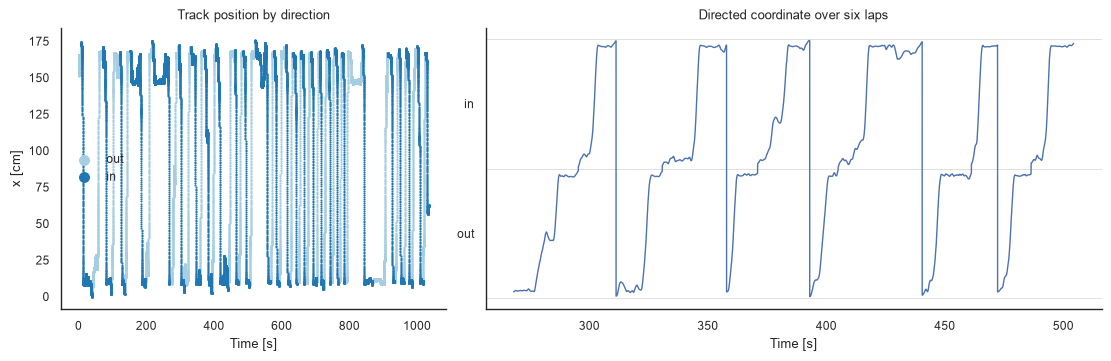

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[1, 1.6]))
segment = segment_of(u_pos)
for index, (name, color) in enumerate(zip(SEGMENT_NAMES, sns.color_palette('Paired', 2))):
    is_segment = segment == index
    axes[0].scatter(position_time[is_segment] - session_start, x[is_segment], s=0.5, color=color,
                    label=name)
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('x [cm]')
axes[0].set_title('Track position by direction')
axes[0].legend(markerscale=10, frameon=False)

shown = (lap_of_pos >= 5) & (lap_of_pos < 11)
axes[1].plot(position_time[shown] - session_start, u_pos[shown], linewidth=1)
label_u_axis(axes[1])
axes[1].set_xlabel('Time [s]')
axes[1].set_title('Directed coordinate over six laps')
sns.despine()

## Bin the spikes and build the training masks

Spikes are counted in `DECODE_BIN_S` bins from `session_start` to `session_end`, and each bin takes the position of the nearest tracking sample. The encoding data is every bin, kept in time order. There are two masks:

* `is_training`, for the place fields: running (speed at least `RUN_SPEED_CM_S`), a valid position, and not in a replay event.
* `continuous_transition_is_training`, for $P$: every bin with a valid position. This keeps the stops at the track ends. A speed filter would cut them out, and the end bins would then have no outgoing transitions.

In [7]:
n_bins = int((session_end - session_start) / DECODE_BIN_S)
bin_time = session_start + (np.arange(n_bins) + 0.5) * DECODE_BIN_S
nearest_sample = np.clip(np.searchsorted(position_time, bin_time), 1, position_time.size - 1)
nearest_sample -= ((bin_time - position_time[nearest_sample - 1])
                   < (position_time[nearest_sample] - bin_time))

n_units = len(spike_times)
spike_bin = np.floor((np.concatenate(spike_times) - session_start) / DECODE_BIN_S).astype(int)
spike_unit = np.concatenate([np.full(len(times), unit) for unit, times in enumerate(spike_times)])
is_kept = (spike_bin >= 0) & (spike_bin < n_bins)
spike_bin, spike_unit = spike_bin[is_kept], spike_unit[is_kept]


def count_spikes(bins):
    # Spike counts (n_bins, n_units) for the given bins of the full time grid.
    row = np.full(n_bins, -1)
    row[bins] = np.arange(bins.size)
    counts = np.zeros((bins.size, n_units), dtype=np.uint8)
    spike_row = row[spike_bin]
    is_in = spike_row >= 0
    np.add.at(counts, (spike_row[is_in], spike_unit[is_in]), 1)
    return counts


is_event = np.zeros(n_bins, dtype=bool)
for start, end in event_intervals:
    is_event[np.searchsorted(bin_time, start):np.searchsorted(bin_time, end, side='right')] = True

position = u_pos[nearest_sample]
spikes = count_spikes(np.arange(n_bins))
lap = lap_of_pos[nearest_sample]

is_running = speed[nearest_sample] >= RUN_SPEED_CM_S
is_training = is_running & np.isfinite(position) & ~is_event
continuous_transition_is_training = np.isfinite(position)

print(f'{n_units} units, {n_bins} encoding bins ({n_bins * DECODE_BIN_S / 60:.1f} min)')
print(f'place fields from {is_training.sum() * DECODE_BIN_S / 60:.1f} min of running, '
      f'P from {continuous_transition_is_training.sum() * DECODE_BIN_S / 60:.1f} min on track')
print(f'median running spikes per unit: {np.median(spikes[is_training].sum(axis=0)):.0f}')

124 units, 344666 encoding bins (17.2 min)
place fields from 6.0 min of running, P from 17.2 min on track
median running spikes per unit: 454


## Check the encoding on held-out laps

Before looking at replay, check that the place fields on $u$ carry the animal's position, including its direction. A `SortedSpikesDecoder` with a `RandomWalk` is fit on three of every four laps, and decodes the fourth. Running bins are scored.

Each held-out lap is decoded on its own. A lap starts at the low-end turn, so it never crosses the wrap from $u \approx 2L$ to $u \approx 0$, which a `RandomWalk` can't follow.

In [8]:
from replay_trajectory_classification import Environment, RandomWalk, SortedSpikesDecoder

is_test_lap = lap % 4 == 3
decoder = SortedSpikesDecoder(
    environment=Environment(place_bin_size=PLACE_BIN_SIZE_CM),
    transition_type=RandomWalk(),
    sorted_spikes_algorithm='spiking_likelihood_kde',
    sorted_spikes_algorithm_params={'position_std': POSITION_STD_CM})
decoder.fit(position, spikes, is_training=is_training & ~is_test_lap)

lap_posteriors = {}
errors, decoded_segment, true_segment = [], [], []
for test_lap in np.unique(lap[is_test_lap]):
    in_lap = lap == test_lap
    posterior = decoder.predict(spikes[in_lap]).acausal_posterior
    decoded_u = posterior.position.values[np.nanargmax(posterior.values, axis=1)]  # off-track bins are NaN
    is_scored = is_training[in_lap]           # running, valid position, not an event
    decoded_x = np.where(decoded_u > track_length, 2 * track_length - decoded_u, decoded_u)
    errors.append(np.abs(decoded_x - x[nearest_sample][in_lap])[is_scored])
    decoded_segment.append(segment_of(decoded_u)[is_scored])
    true_segment.append(segment_of(position[in_lap])[is_scored])
    lap_posteriors[test_lap] = posterior
errors = np.concatenate(errors)
decoded_segment, true_segment = np.concatenate(decoded_segment), np.concatenate(true_segment)
print(f'{len(lap_posteriors)} held-out laps, {errors.size * DECODE_BIN_S:.0f} s of running')
print(f'median error in x {np.median(errors):.1f} cm, '
      f'{np.mean(errors < 20):.1%} of bins within 20 cm')
print(f'direction correct in {np.mean(decoded_segment == true_segment):.1%} of running bins')

6 held-out laps, 79 s of running
median error in x 4.8 cm, 95.1% of bins within 20 cm
direction correct in 83.2% of running bins


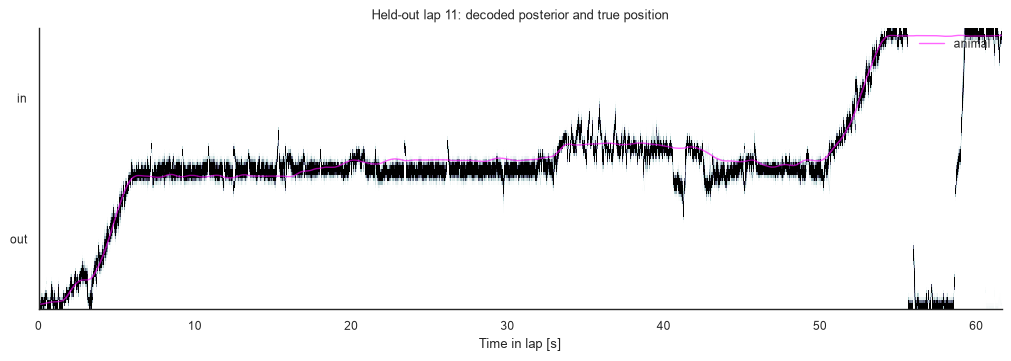

In [9]:
shown_lap = list(lap_posteriors)[2]
posterior = lap_posteriors[shown_lap]
lap_time = np.arange(posterior.shape[0]) * DECODE_BIN_S
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
ax.pcolormesh(lap_time, posterior.position.values, posterior.values.T,
              cmap='bone_r', vmin=0.0, vmax=0.1, shading='nearest', rasterized=True)
ax.plot(lap_time, position[lap == shown_lap], color='magenta', linewidth=1, alpha=0.6,
        label='animal')
label_u_axis(ax)
ax.set_xlabel('Time in lap [s]')
ax.set_title(f'Held-out lap {shown_lap}: decoded posterior and true position')
ax.legend(frameon=False, loc='upper right')
sns.despine()

## Fit the classifier

The `tcm_sr` dynamic is built from $P$, which is counted over `MOVEMENT_TIME_STEP_S` of behavior. The figure shows $P$, and the starting kernel from three positions: mid outbound, the far end, and the near end of the inbound run. The last one shows the kernel continuing past the wrap into the start of the outbound run.

In [10]:
from replay_trajectory_classification import (
    DiagonalDiscrete, Identity, SortedSpikesClassifier, TCM_SR, Uniform)


def make_classifier(continuous):
    return SortedSpikesClassifier(
        environments=Environment(place_bin_size=PLACE_BIN_SIZE_CM),
        continuous_transition_types=[[Identity(), continuous, Uniform()],
                                     [Identity(), continuous, Uniform()],
                                     [Uniform(),  Uniform(),  Uniform()]],
        discrete_transition_type=DiagonalDiscrete(DISCRETE_DIAGONAL),
        sorted_spikes_algorithm='spiking_likelihood_kde',
        sorted_spikes_algorithm_params={'position_std': POSITION_STD_CM})


def make_tcm_sr(gamma=INITIAL_GAMMA, asymmetry=INITIAL_ASYMMETRY, **kwargs):
    return TCM_SR(gamma=gamma, asymmetry=asymmetry, movement_time_step=MOVEMENT_TIME_STEP_S,
                  sampling_frequency=SAMPLING_FREQUENCY, **kwargs)


def horizon(gamma):
    return MOVEMENT_TIME_STEP_S / (1.0 - gamma)


fit_args = dict(position=position, spikes=spikes, is_training=is_training,
                continuous_transition_is_training=continuous_transition_is_training)
tcm_sr = make_tcm_sr(learn=('gamma', 'asymmetry'))
classifier = make_classifier(tcm_sr)
classifier.fit(**fit_args)

environment = classifier.environments[0]
bin_centers = environment.place_bin_centers_.squeeze()
interior = environment.is_track_interior_.ravel(order='F')
initial_kernel = classifier.continuous_state_transition_[1, 1].copy()
print(f'{bin_centers.size} position bins, {interior.sum()} on the track')
print(f'starting kernel: gamma={tcm_sr.gamma}, horizon {horizon(tcm_sr.gamma) * 1e3:.0f} ms, '
      f'asymmetry={tcm_sr.asymmetry}')

88 position bins, 88 on the track
starting kernel: gamma=0.7, horizon 333 ms, asymmetry=0.5


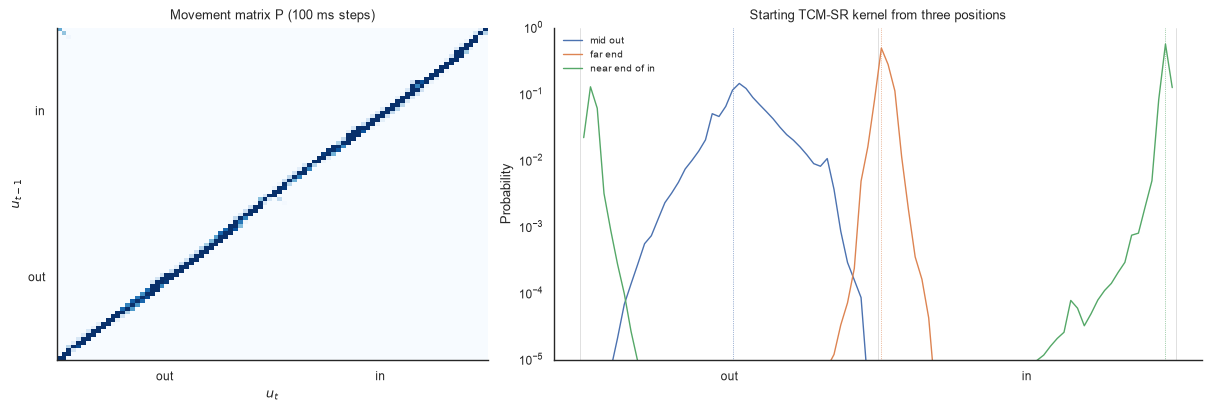

In [11]:
kernel_sources = {
    'mid out': track_length / 2,
    'far end': track_length,
    'near end of in': np.nanmax(u_pos) - 4.0,
}


def nearest_bin(u):
    candidates = np.flatnonzero(interior)
    return candidates[np.argmin(np.abs(bin_centers[candidates] - u))]


def plot_kernel_rows(ax, kernels):
    for (name, u), color in zip(kernel_sources.items(), sns.color_palette(n_colors=3)):
        row = nearest_bin(u)
        for (label, kernel), style in zip(kernels.items(), ['-', '--']):
            ax.plot(bin_centers, kernel[row], color=color, linestyle=style, linewidth=1,
                    label=f'{name} ({label})' if len(kernels) > 1 else name)
        ax.axvline(bin_centers[row], color=color, linewidth=0.5, linestyle=':')
    label_u_axis(ax, axis='x')
    ax.set_yscale('log')
    ax.set_ylim((1e-5, 1.0))
    ax.set_ylabel('Probability')
    ax.legend(frameon=False, fontsize=7)


fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[1, 1.5]))
movement = np.zeros((bin_centers.size, bin_centers.size))
movement[np.ix_(interior, interior)] = tcm_sr.movement_
axes[0].pcolormesh(bin_centers, bin_centers, movement, cmap='Blues', vmax=0.2,
                   shading='nearest', rasterized=True)
label_u_axis(axes[0], axis='x')
label_u_axis(axes[0], axis='y')
axes[0].set_xlabel(r'$u_t$')
axes[0].set_ylabel(r'$u_{t-1}$')
axes[0].set_title(f'Movement matrix P ({MOVEMENT_TIME_STEP_S * 1e3:.0f} ms steps)')
plot_kernel_rows(axes[1], {'start': initial_kernel})
axes[1].set_title('Starting TCM-SR kernel from three positions')
sns.despine()

## Build the replay data

Each event is cut into `DECODE_BIN_S` bins, and the events are concatenated. Alternate events form the training set, on which EM is run, and the test set, which is held out for the comparison at the end. There's no boundary between events in the concatenation. Each junction adds one transition that doesn't belong to either event, about 1 in 50 for events of this length.

In [12]:
event_bins = [np.arange(int(np.ceil((start - session_start) / DECODE_BIN_S)),
                        int(np.ceil((end - session_start) / DECODE_BIN_S)))
              for start, end in event_intervals]
event_id = np.concatenate([np.full(bins.size, i) for i, bins in enumerate(event_bins)])
replay_spikes = count_spikes(np.concatenate(event_bins))
is_train_event = event_id % 2 == 0
replay = {
    'train': dict(spikes=replay_spikes[is_train_event], event=event_id[is_train_event]),
    'test': dict(spikes=replay_spikes[~is_train_event], event=event_id[~is_train_event]),
}
for name, data in replay.items():
    data['time'] = np.arange(data['spikes'].shape[0]) * DECODE_BIN_S
    print(f"{name}: {np.unique(data['event']).size} events, {data['spikes'].shape[0]} bins, "
          f"{data['spikes'].sum() / data['spikes'].shape[0]:.2f} spikes per bin")

train: 99 events, 6018 bins, 1.58 spikes per bin
test: 99 events, 5976 bins, 1.60 spikes per bin


## Fit `gamma` and `asymmetry` by EM

`learn` names the parameters to fit, and `estimate_discrete_transition=False` holds the discrete matrix fixed. The initial conditions are re-estimated, as `estimate_parameters` does by default.

In [13]:
start = clock.time()
train_results, data_log_likelihoods = classifier.estimate_parameters(
    fit_args=fit_args,
    predict_args=dict(spikes=replay['train']['spikes'], time=replay['train']['time'],
                      state_names=STATE_NAMES),
    estimate_continuous_transition=True,
    estimate_discrete_transition=False,
    max_iter=EM_MAX_ITER,
    tolerance=EM_TOLERANCE,
    verbose=False,
)
history = [step[((0, 1), (1, 1))] for step in classifier.continuous_transition_parameter_history_]
gammas = [INITIAL_GAMMA] + [step['gamma'] for step in history]
asymmetries = [INITIAL_ASYMMETRY] + [step['asymmetry'] for step in history]
print(f'{len(history)} iterations in {(clock.time() - start) / 60:.1f} min')
print(f'gamma {INITIAL_GAMMA} -> {tcm_sr.gamma:.4f} '
      f'(horizon {horizon(INITIAL_GAMMA) * 1e3:.0f} -> {horizon(tcm_sr.gamma) * 1e3:.0f} ms)')
print(f'asymmetry {INITIAL_ASYMMETRY} -> {tcm_sr.asymmetry:.3f}')
print(f'data log likelihood gain {data_log_likelihoods[-1] - data_log_likelihoods[0]:.1f} nats; '
      f'smallest step {np.diff(data_log_likelihoods).min():.3f}')

27 iterations in 0.7 min
gamma 0.7 -> 0.5617 (horizon 333 -> 228 ms)
asymmetry 0.5 -> 0.189
data log likelihood gain 41.0 nats; smallest step 0.005


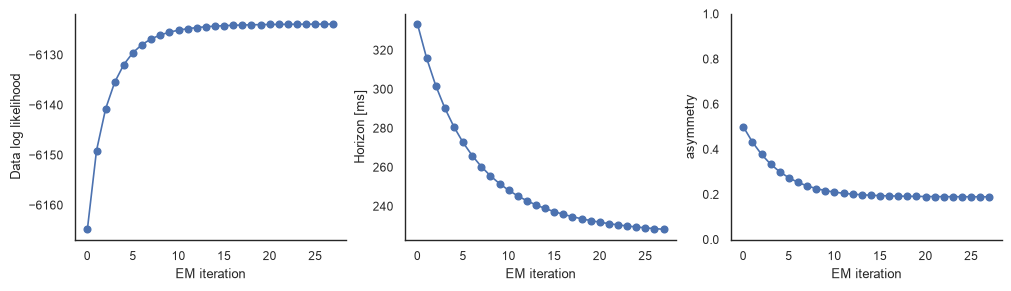

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), constrained_layout=True)
iterations = np.arange(len(data_log_likelihoods))
axes[0].plot(iterations, data_log_likelihoods, marker='o')
axes[0].set_ylabel('Data log likelihood')
axes[1].plot(iterations, [horizon(g) * 1e3 for g in gammas], marker='o')
axes[1].set_ylabel('Horizon [ms]')
axes[2].plot(iterations, asymmetries, marker='o')
axes[2].set_ylim((0, 1))
axes[2].set_ylabel('asymmetry')
for ax in axes:
    ax.set_xlabel('EM iteration')
sns.despine()

## Check EM against a direct maximization

EM climbs the marginal likelihood of the training events, so it should end near the maximum of that likelihood. To check, `score_continuous_transition` sets candidate parameters, rebuilds the kernel, and runs only the forward pass on the cached spike likelihood of the training PBEs. That gives the data log likelihood itself, without the E-step. Each call costs one forward pass.

A coarse grid over horizon and `asymmetry` comes first. Nelder–Mead then refines from the best grid point, in log horizon and `asymmetry`.

In [15]:
from scipy.optimize import minimize

grid_horizons = np.array([0.15, 0.4, 1.0, 2.0, 5.0])   # seconds
grid_asymmetries = np.array([0.2, 0.4, 0.6, 0.8])


def gamma_of(horizon_s):
    return 1.0 - MOVEMENT_TIME_STEP_S / horizon_s


start = clock.time()
scores = np.array([[classifier.score_continuous_transition(tcm_sr, gamma=gamma_of(h), asymmetry=a)
                    for h in grid_horizons] for a in grid_asymmetries])
em_score = classifier.score_continuous_transition(tcm_sr)
best = np.unravel_index(scores.argmax(), scores.shape)
print(f'{scores.size} grid points in {(clock.time() - start) / 60:.1f} min')
print(f'best grid point: horizon {grid_horizons[best[1]]:g} s, asymmetry {grid_asymmetries[best[0]]}, '
      f'and the EM estimate is {em_score - scores.max():.1f} nats above it')

20 grid points in 0.1 min
best grid point: horizon 0.15 s, asymmetry 0.2, and the EM estimate is 24.1 nats above it


23 evaluations in 0.1 min
maximum likelihood: horizon 0.23 s (gamma 0.5559), asymmetry 0.192
0.0 nats above the EM estimate, 24.2 above the best grid point


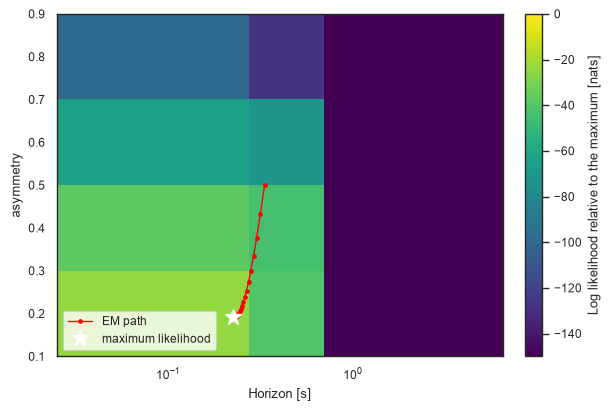

In [16]:
def negative_log_likelihood(parameters):
    log_horizon, asymmetry = parameters
    if not (MOVEMENT_TIME_STEP_S < np.exp(log_horizon) and 0.0 <= asymmetry <= 1.0):
        return np.inf
    return -classifier.score_continuous_transition(
        tcm_sr, gamma=gamma_of(np.exp(log_horizon)), asymmetry=asymmetry)


start = clock.time()
x0 = np.array([np.log(grid_horizons[best[1]]), grid_asymmetries[best[0]]])
refined = minimize(negative_log_likelihood, x0, method='Nelder-Mead',
                   options=dict(maxfev=25, xatol=0.02, fatol=0.5,
                                initial_simplex=x0 + np.array([[0, 0], [0.5, 0], [0, 0.1]])))
ml_horizon, ml_asymmetry = np.exp(refined.x[0]), refined.x[1]
ml_score = -refined.fun
print(f'{refined.nfev} evaluations in {(clock.time() - start) / 60:.1f} min')
print(f'maximum likelihood: horizon {ml_horizon:.2f} s (gamma {gamma_of(ml_horizon):.4f}), '
      f'asymmetry {ml_asymmetry:.3f}')
print(f'{ml_score - em_score:.1f} nats above the EM estimate, '
      f'{ml_score - scores.max():.1f} above the best grid point')

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
mesh = ax.pcolormesh(grid_horizons, grid_asymmetries, scores - ml_score,
                     vmin=-150, vmax=0, cmap='viridis', shading='nearest')
fig.colorbar(mesh, ax=ax, label='Log likelihood relative to the maximum [nats]')
ax.plot([horizon(g) for g in gammas], asymmetries, color='red', marker='.', linewidth=1,
        label='EM path')
ax.plot(ml_horizon, ml_asymmetry, marker='*', color='white', markersize=12,
        linestyle='none', label='maximum likelihood')
ax.set_xscale('log')
ax.set_xlabel('Horizon [s]')
ax.set_ylabel('asymmetry')
ax.legend(frameon=True, facecolor='white', loc='lower left')

## Held-out comparison

The test PBEs were not used by EM. Each model below decodes them with the same place fields and the same discrete transition, and differs only in the continuous dynamic:

* `TCM_SR` at the EM estimate;
* `TCM_SR` at the direct maximum likelihood estimate;
* the starting `TCM_SR`;
* a `RandomWalk`, the package's usual continuous dynamic, with its variance chosen on the training PBEs from a small grid;
* a `RandomWalk` with the package's default variance, 6 cm².

All of them use the initial conditions that EM estimated.

In [17]:
def test_log_likelihood(model):
    model.initial_conditions_ = classifier.initial_conditions_
    return float(model.predict(spikes=replay['test']['spikes'], time=replay['test']['time'],
                               state_names=STATE_NAMES,
                               is_compute_acausal=False).data_log_likelihood)


random_walk_train = {}
for movement_var in [1.0, 4.0, 16.0, 64.0]:
    model = make_classifier(RandomWalk(movement_var=movement_var)).fit(**fit_args)
    model.initial_conditions_ = classifier.initial_conditions_
    random_walk_train[movement_var] = float(model.predict(
        spikes=replay['train']['spikes'], state_names=STATE_NAMES,
        is_compute_acausal=False).data_log_likelihood)
best_var = max(random_walk_train, key=random_walk_train.get)
print('RandomWalk train log likelihood by movement_var:',
      {var: round(ll, 1) for var, ll in random_walk_train.items()})

ml_classifier = make_classifier(make_tcm_sr(gamma=gamma_of(ml_horizon), asymmetry=ml_asymmetry))
ml_classifier.fit(**fit_args)
comparison = pd.Series({
    'TCM_SR, EM': test_log_likelihood(classifier),
    'TCM_SR, maximum likelihood': test_log_likelihood(ml_classifier),
    'TCM_SR, start': test_log_likelihood(make_classifier(make_tcm_sr()).fit(**fit_args)),
    f'RandomWalk (var={best_var:g})':
        test_log_likelihood(make_classifier(RandomWalk(movement_var=best_var)).fit(**fit_args)),
    f'RandomWalk (var={RandomWalk().movement_var:g}, default)':
        test_log_likelihood(make_classifier(RandomWalk()).fit(**fit_args)),
}, name='test log likelihood')
n_test_events = np.unique(replay['test']['event']).size
pd.DataFrame({'test log likelihood': comparison,
              'vs EM, nats per event':
                  (comparison - comparison.iloc[0]) / n_test_events})

RandomWalk train log likelihood by movement_var: {1.0: -6745.7, 4.0: -6336.3, 16.0: -6232.3, 64.0: -6322.4}


,test log likelihood,"vs EM, nats per event"
"TCM_SR, EM",-6064.097632,0.000000
"TCM_SR, maximum likelihood",-6063.683743,0.004181
"TCM_SR, start",-6080.070403,-0.161341
RandomWalk (var=16),-6215.230094,-1.526591
"RandomWalk (var=6, default)",-6266.407410,-2.043533


## The fitted kernel and the classification

From here on the model is `TCM_SR` at the EM estimate. The first figure overlays its kernel on the starting one, from the same three positions. The second shows the whole kernel next to the default `RandomWalk`, and their difference. The test events are then classified. The four with the highest mean P(tcm_sr) are shown, then four chosen examples, each with the posterior over $u$ and the probability of each dynamic.

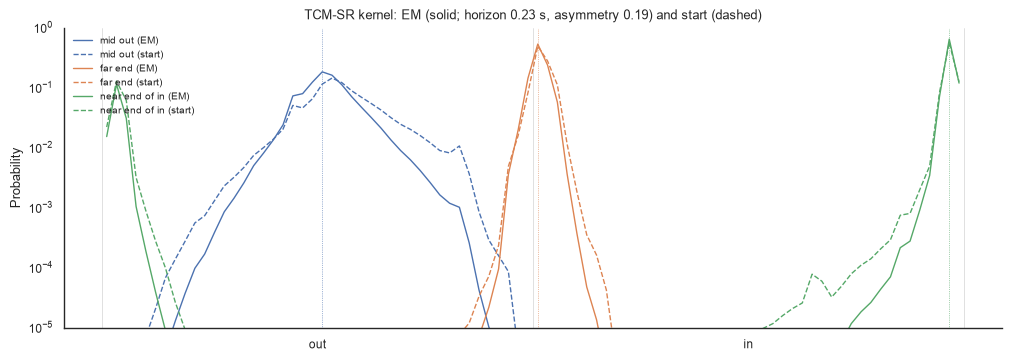

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
em_kernel = classifier.continuous_state_transition_[1, 1]
plot_kernel_rows(ax, {'EM': em_kernel, 'start': initial_kernel})
ax.set_title(f'TCM-SR kernel: EM (solid; horizon {horizon(tcm_sr.gamma):.2f} s, '
             f'asymmetry {tcm_sr.asymmetry:.2f}) and start (dashed)')
sns.despine()

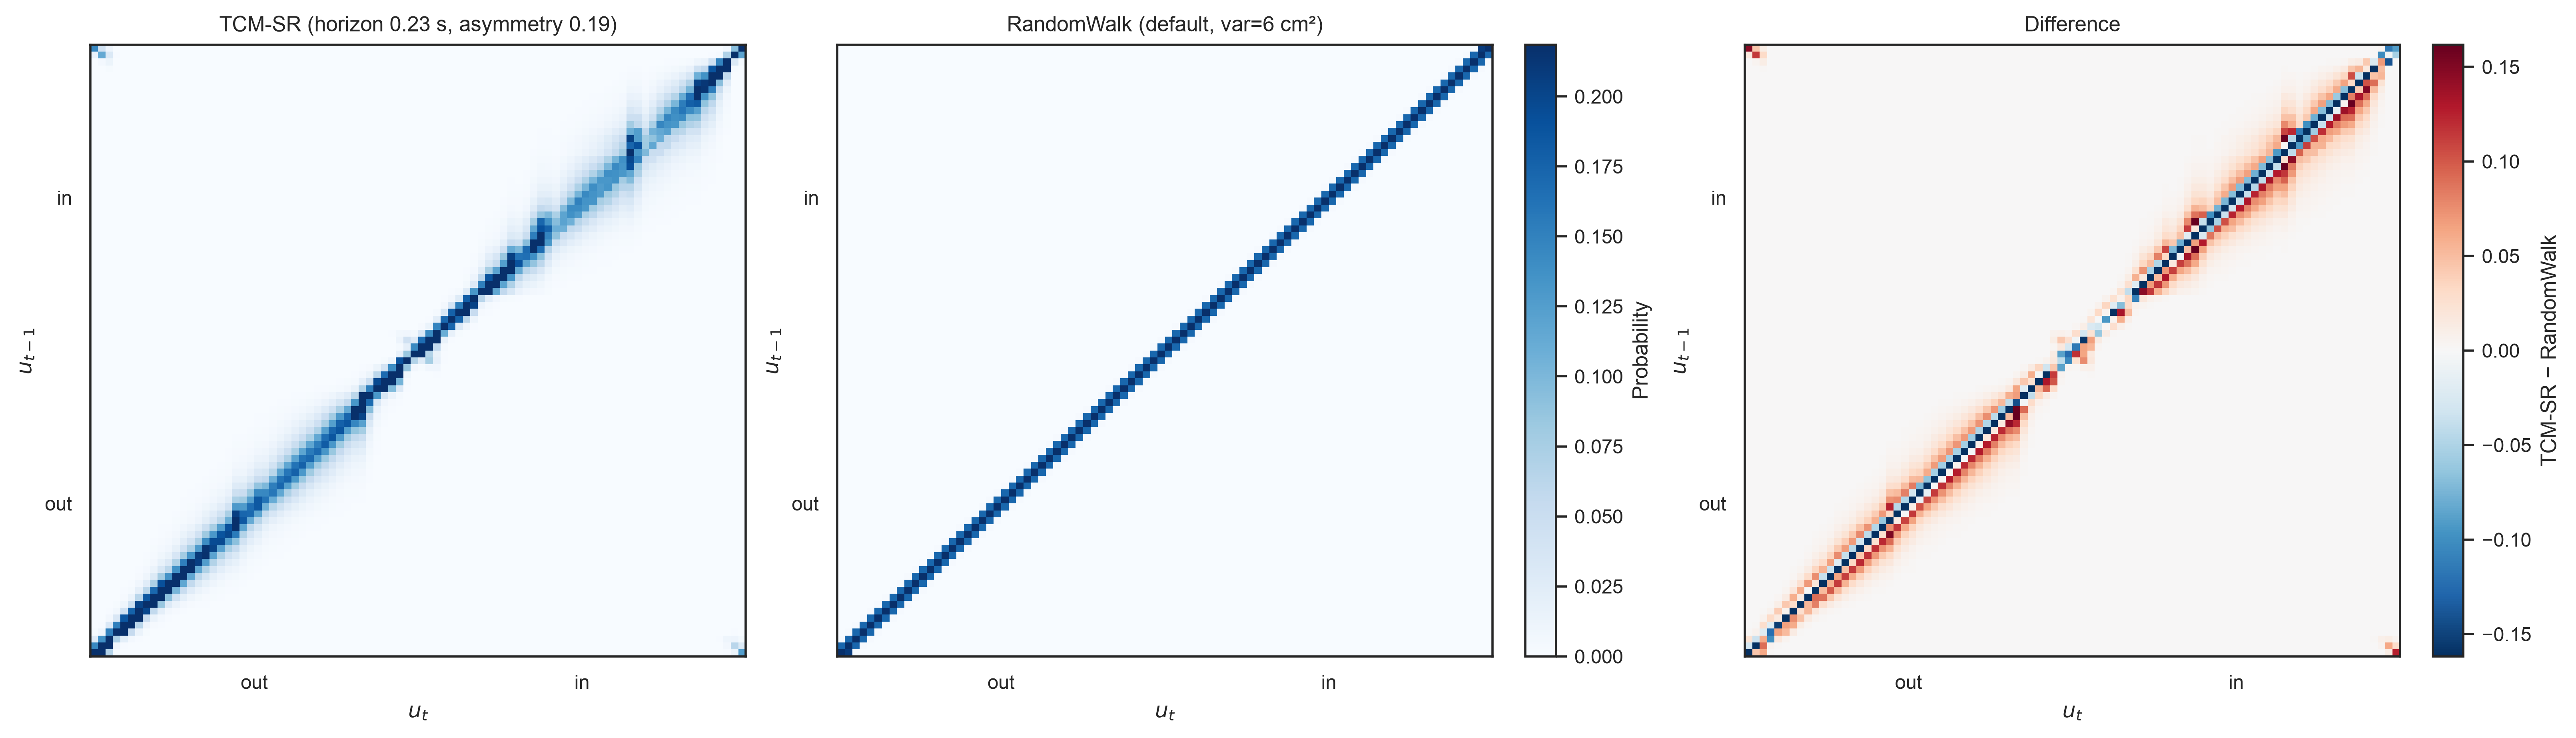

In [19]:
default_random_walk = RandomWalk()
random_walk_kernel = default_random_walk.make_state_transition((environment,))
kernels = {
    f'TCM-SR (horizon {horizon(tcm_sr.gamma):.2f} s, asymmetry {tcm_sr.asymmetry:.2f})': em_kernel,
    f'RandomWalk (default, var={default_random_walk.movement_var:g} cm²)': random_walk_kernel,
}
vmax = np.quantile(em_kernel[em_kernel > 0], 0.99)
difference = em_kernel - random_walk_kernel
dmax = np.quantile(np.abs(difference[difference != 0]), 0.99)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True, dpi=400)
for ax, (title, kernel) in zip(axes, kernels.items()):
    mesh = ax.pcolormesh(bin_centers, bin_centers, kernel, cmap='Blues', vmin=0.0, vmax=vmax,
                         shading='nearest', rasterized=True)
    ax.set_title(title)
fig.colorbar(mesh, ax=axes[1], label='Probability')
mesh = axes[2].pcolormesh(bin_centers, bin_centers, difference, cmap='RdBu_r',
                          vmin=-dmax, vmax=dmax, shading='nearest', rasterized=True)
fig.colorbar(mesh, ax=axes[2], label='TCM-SR − RandomWalk')
axes[2].set_title('Difference')
for ax in axes:
    label_u_axis(ax, axis='x')
    label_u_axis(ax, axis='y')
    ax.set_xlabel(r'$u_t$')
    ax.set_ylabel(r'$u_{t-1}$')

test events by dynamic with the highest mean probability:
winner
tcm_sr        86
stationary    11
fragmented     2


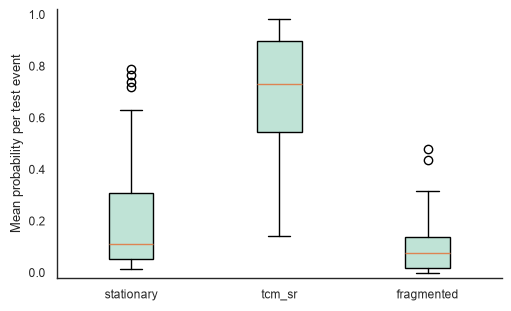

In [20]:
test_results = classifier.predict(spikes=replay['test']['spikes'],
                                  time=replay['test']['time'], state_names=STATE_NAMES)
state_probability = test_results.acausal_posterior.sum('position').values
event_probability = pd.DataFrame(state_probability, columns=STATE_NAMES).groupby(
    replay['test']['event']).mean()
event_probability['winner'] = event_probability[STATE_NAMES].idxmax(axis=1)
print('test events by dynamic with the highest mean probability:')
print(event_probability.winner.value_counts().to_string())

fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)
ax.boxplot([event_probability[state] for state in STATE_NAMES], patch_artist=True,
           boxprops=dict(facecolor='#bfe3d6'))
ax.set_xticks(range(1, len(STATE_NAMES) + 1), STATE_NAMES)
ax.set_ylabel('Mean probability per test event')
ax.set_ylim((-0.02, 1.02))
sns.despine()

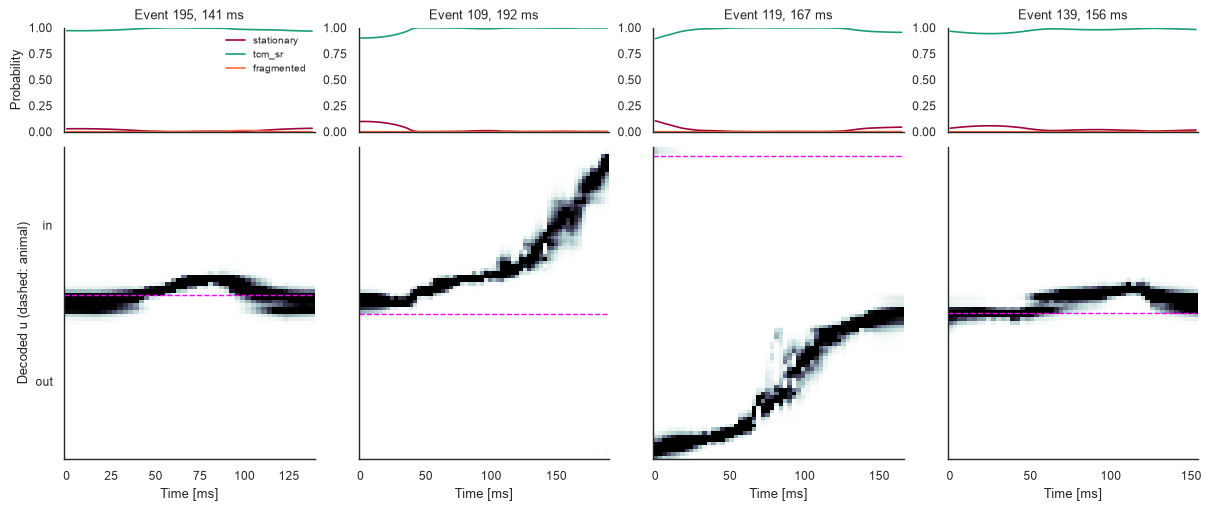

In [21]:
STATE_COLORS = {'stationary': '#9f043a', 'tcm_sr': '#1b9e77', 'fragmented': '#ff6944'}
position_posterior = test_results.acausal_posterior.sum('state').values
shown_events = event_probability.sort_values('tcm_sr', ascending=False).index[:4]

fig, axes = plt.subplots(2, len(shown_events), figsize=(12, 5), sharex='col',
                         gridspec_kw=dict(height_ratios=[1, 3]), constrained_layout=True)
for column, event in enumerate(shown_events):
    is_event = replay['test']['event'] == event
    event_time = np.arange(is_event.sum()) * DECODE_BIN_S * 1e3
    for state in STATE_NAMES:
        axes[0, column].plot(event_time, state_probability[is_event, STATE_NAMES.index(state)],
                             color=STATE_COLORS[state], label=state)
    axes[0, column].set_ylim((0, 1))
    axes[0, column].set_title(f'Event {event}, {event_duration[event] * 1e3:.0f} ms')
    axes[1, column].pcolormesh(event_time, bin_centers, position_posterior[is_event].T,
                               cmap='bone_r', vmin=0.0, vmax=0.1, shading='nearest',
                               rasterized=True)
    animal_u = u_pos[np.searchsorted(position_time, event_intervals[event, 0])]
    axes[1, column].axhline(animal_u, color='magenta', linewidth=1, linestyle='--')
    label_u_axis(axes[1, column])
    axes[1, column].set_xlabel('Time [ms]')
    if column > 0:
        axes[1, column].set_yticklabels([])
axes[0, 0].set_ylabel('Probability')
axes[0, 0].legend(frameon=False, fontsize=7)
axes[1, 0].set_ylabel('Decoded u (dashed: animal)')
sns.despine()

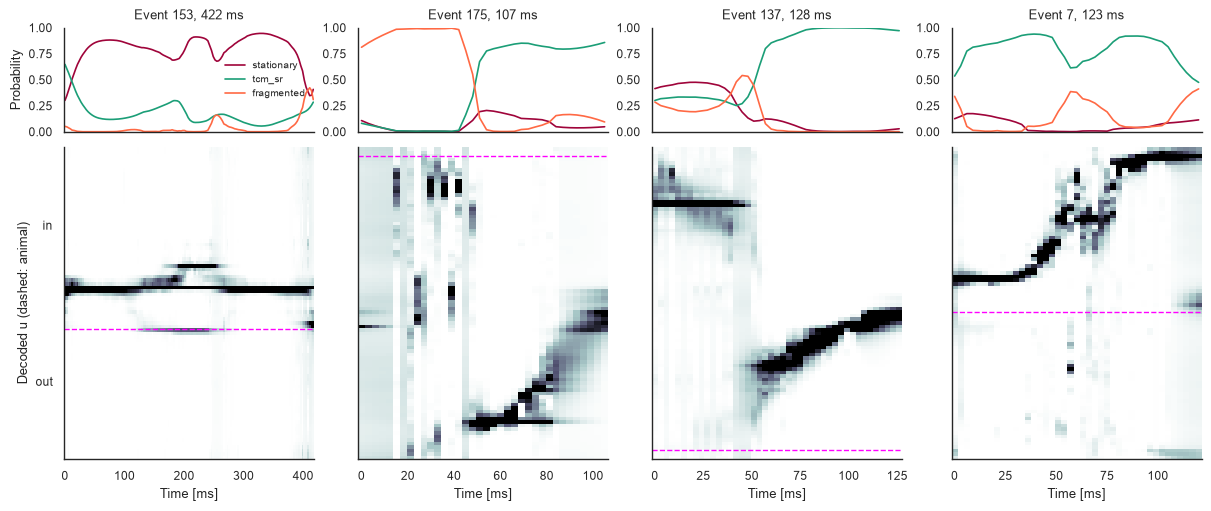

In [22]:
STATE_COLORS = {'stationary': '#9f043a', 'tcm_sr': '#1b9e77', 'fragmented': '#ff6944'}
position_posterior = test_results.acausal_posterior.sum('state').values
shown_events = [153, 175, 137, 7] #
# shown_events = event_probability.sample(4).index

fig, axes = plt.subplots(2, len(shown_events), figsize=(12, 5), sharex='col',
                         gridspec_kw=dict(height_ratios=[1, 3]), constrained_layout=True)
for column, event in enumerate(shown_events):
    is_event = replay['test']['event'] == event
    event_time = np.arange(is_event.sum()) * DECODE_BIN_S * 1e3
    for state in STATE_NAMES:
        axes[0, column].plot(event_time, state_probability[is_event, STATE_NAMES.index(state)],
                             color=STATE_COLORS[state], label=state)
    axes[0, column].set_ylim((0, 1))
    axes[0, column].set_title(f'Event {event}, {event_duration[event] * 1e3:.0f} ms')
    axes[1, column].pcolormesh(event_time, bin_centers, position_posterior[is_event].T,
                               cmap='bone_r', vmin=0.0, vmax=0.1, shading='nearest',
                               rasterized=True)
    animal_u = u_pos[np.searchsorted(position_time, event_intervals[event, 0])]
    axes[1, column].axhline(animal_u, color='magenta', linewidth=1, linestyle='--')
    label_u_axis(axes[1, column])
    axes[1, column].set_xlabel('Time [ms]')
    if column > 0:
        axes[1, column].set_yticklabels([])
axes[0, 0].set_ylabel('Probability')
axes[0, 0].legend(frameon=False, fontsize=7)
axes[1, 0].set_ylabel('Decoded u (dashed: animal)')
sns.despine()

## Summary

**Data.** 124 excitatory units over 17 min and 27 laps. There are 198 PBEs (median 155 ms); 162 of them happen at a track end. 99 are used for fitting and 99 are held out. There are about 1.6 spikes per 3 ms bin across all cells.

**Coordinate.** The directed coordinate is the simulation's loop. $P$ is one diagonal from $u = 0$ to $2L$, and the only jump is the wrap at the low-end turn. It carries the end of each inbound run into the start of the next outbound run.

**Encoding.** On held-out laps, the place fields decode the animal's track position with a median error of 4.8 cm, and 95% of running bins are within 20 cm. The direction is right in 83% of running bins. Near the ends, the outbound and inbound fields overlap more.

**EM.** From `gamma=0.7` (a 333 ms horizon) and `asymmetry=0.5`, EM converges in 27 iterations (about 40 s). The data log likelihood rises at every iteration, by 41 nats in all. EM ends at a **228 ms horizon** (`gamma=0.56`) and **`asymmetry=0.19`**.

**EM reaches the maximum.** Maximizing the marginal likelihood directly lands at the same point (0.23 s, 0.19), within 0.01 nats of the EM estimate. With 100 ms steps of $P$, the kernel looks only about two steps of behavior ahead. Most of its weight is on the symmetric $M^\top M$ part, so it allows forward and reverse sequences almost equally.

**Held out.** On the test PBEs, the EM `TCM_SR` beats the starting kernel by 0.16 nats per event, the best `RandomWalk` (variance 16 cm²) by 1.5 nats per event, and the default `RandomWalk` (6 cm²) by 2.0.

**Classification.** With the EM kernel, 86 of 99 test events are mostly `tcm_sr`, 11 mostly `stationary`, and 2 mostly `fragmented`. The top events are clean sequences. Some stay near the animal, and some run the length of the track. The chosen examples show the other cases: a long stationary event, events that start fragmented or stationary and switch to a sequence, and a sequence with brief fragmented excursions.
